# Clasificación de tipos de vehículo: MLP, CNN propia y transfer learning

**Proyecto individual** · Grado en Ingeniería Informática · Universidad Carlos III de Madrid

Este notebook compara tres enfoques de redes neuronales para clasificar imágenes de vehículos en 7 tipos, de un perceptrón multicapa a transfer learning con MobileNetV2, con TensorFlow/Keras.

**Datos:** dataset de Kaggle con 15.645 imágenes en 7 clases desbalanceadas (de 577 imágenes de *Big Truck* a 4.657 de *City Car*). Partición 80/20 en entrenamiento (12.516) y validación (3.129). El dataset no se incluye en el repositorio.

| Modelo | Entrada | Exactitud en validación |
| :--- | :--- | :---: |
| Clase mayoritaria (baseline) | — | 29,8 % |
| MLP | 64×64, escala de grises | ≈ 54 % |
| CNN propia, sin augmentation | 128×128, RGB | ≈ 86 % (según la curva) |
| **CNN propia + augmentation + pesos de clase** | 128×128, RGB | **92,4 %** |
| MobileNetV2 (transfer learning + fine-tuning) | 224×224, RGB | 89,6 % |

Las conclusiones y las limitaciones de la evaluación están en la última sección.

**Nota sobre la ejecución:** el notebook se ejecutó en varias sesiones, por lo que los contadores de ejecución no son consecutivos y algunas salidas proceden de ejecuciones anteriores. Cada caso se indica junto a la celda correspondiente.

## 1. Configuración

In [1]:
import tensorflow as tf

# Ruta del dataset: una carpeta por clase
base_dir = 'data/archive'

BATCH_SIZE = 64

# Reserva de memoria dinámica en la GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
  try:
    tf.config.experimental.set_memory_growth(gpus[0], True)
    print("Crecimiento de memoria dinámica configurado para la GPU.")
  except RuntimeError as e:
    print(e)

Crecimiento de memoria dinámica configurado para la GPU.


**Análisis previo de resoluciones.** El script `analyze_resolutions.py` del repositorio recorre el dataset, dibuja la distribución de anchos y altos por clase y sugiere un tamaño de entrada para la red a partir de la mediana y del percentil 75 del ancho. Sirvió para elegir los tamaños de entrada de los modelos.

## 2. Perceptrón multicapa (MLP)

Un MLP recibe la imagen aplanada como vector, así que el número de pesos de la primera capa crece con el tamaño de la entrada. Con imágenes RGB de 64×64 (12.288 valores) y una primera capa oculta de 128 neuronas habría 12.288 × 128 = 1.572.864 pesos solo en esa capa. Pasando las imágenes a escala de grises (4.096 valores) se reducen a 524.288, un tercio.

In [12]:
VALIDATION_AMOUNT = 0.2
IMAGE_SIZE = (64, 64)

train_dataset_mlp = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',
    label_mode='int',
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    interpolation='bilinear',
    color_mode='grayscale',
    shuffle=True,
    validation_split=VALIDATION_AMOUNT,
    subset='training',
    seed=42 
)

validation_dataset_mlp = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',
    label_mode='int',
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    interpolation='bilinear',
    color_mode='grayscale',
    shuffle=True, 
    validation_split=VALIDATION_AMOUNT, 
    subset='validation',               
    seed=42                            
)

Found 15645 files belonging to 7 classes.
Using 12516 files for training.
Found 15645 files belonging to 7 classes.
Using 3129 files for validation.


**Desbalanceo de clases.** El dataset completo tiene esta distribución:

| Clase | Imágenes |
| :--- | ---: |
| City Car | 4.657 |
| Multi Purpose Vehicle | 2.649 |
| Sedan | 2.619 |
| Van | 2.167 |
| Sport Utility Vehicle | 1.826 |
| Truck | 1.150 |
| Big Truck | 577 |

La clase mayoritaria tiene 8 veces más imágenes que la minoritaria. Para que el modelo no se limite a aprender las clases grandes, la pérdida se pondera con la frecuencia inversa de cada clase: peso = total / (número de clases × imágenes de la clase).

In [14]:
import numpy as np
from sklearn.utils import class_weight

total_counts = {
    'Van': 2167,
    'Truck': 1150,
    'Sport Utility Vehicle': 1826,
    'Sedan': 2619,
    'Multi Purpose Vehicle': 2649,
    'City Car': 4657,
    'Big Truck': 577
}

# Pesos de clase a partir del conteo de imágenes por clase.
# El orden alfabético coincide con el que asigna image_dataset_from_directory.
class_names = sorted(list(total_counts.keys()))
n_classes = len(class_names)

print(f"\nClases en orden (usando claves de conteo): {class_names}")

total_train_samples = 0
train_counts = []

for class_name in class_names:
    # Obtenemos el conteo total para esta clase
    total_count = total_counts[class_name]

    # Estimación de las muestras de entrenamiento (80 % del total)
    n_train = int(total_count * (1 - VALIDATION_AMOUNT))

    train_counts.append(n_train)
    total_train_samples += n_train

print(f"\nTotal de muestras de entrenamiento: {total_train_samples}")
print(f"Conteos de entrenamiento por clase: {train_counts}")

class_weight_dict = {}

for i in range(n_classes):
    # Fórmula de frecuencia inversa: total_muestras / (num_clases * conteo_de_la_clase)
    weight = total_train_samples / (n_classes * train_counts[i])
    class_weight_dict[i] = weight

print("\n--- Pesos de clase calculados ---")
print(class_weight_dict)


Clases en orden (usando claves de conteo): ['Big Truck', 'City Car', 'Multi Purpose Vehicle', 'Sedan', 'Sport Utility Vehicle', 'Truck', 'Van']

Total de muestras de entrenamiento: 12513
Conteos de entrenamiento por clase: [461, 3725, 2119, 2095, 1460, 920, 1733]

--- Pesos de clase calculados ---
{0: 3.877595289742795, 1: 0.4798849472674976, 2: 0.8435919908312547, 3: 0.8532560518240709, 4: 1.2243639921722114, 5: 1.9430124223602485, 6: 1.0314895721704724}


**Entrenamiento.** Dos capas ocultas (128 y 64 neuronas, ReLU), Adam y la pérdida ponderada. *El registro de abajo corresponde a una reejecución que se interrumpió manualmente en la época 35 de 70 (se muestra hasta la última época completa). Las curvas de la celda siguiente proceden de una ejecución anterior completa de 70 épocas, que terminó con una exactitud en validación de aproximadamente el 54 %.*

In [5]:
num_classes = len(total_counts)

# Caché en memoria y precarga de batches
train_dataset_mlp = train_dataset_mlp.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
validation_dataset_mlp = validation_dataset_mlp.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

model_mlp = tf.keras.Sequential([
    # Normalización de [0, 255] a [0, 1]
    tf.keras.layers.Rescaling(1./255, input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 1)),
    # Aplanado de la imagen a un vector
    tf.keras.layers.Flatten(),

    # Capas densas
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax') # Capa de salida
])

model_mlp.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_mlp.summary()

print("\n--- Iniciando Entrenamiento del MLP ---")

history_mlp = model_mlp.fit(
    train_dataset_mlp, #se pasa generador de train
    validation_data=validation_dataset_mlp, #se pasa generador de test
    epochs=70,
    verbose=1,
    class_weight=class_weight_dict
)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 64, 64, 1)         0         
                                                                 
 flatten (Flatten)           (None, 4096)              0         
                                                                 
 dense (Dense)               (None, 128)               524416    
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dense_2 (Dense)             (None, 7)                 455       
                                                                 
Total params: 533127 (2.03 MB)
Trainable params: 533127 (2.03 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________

--- Iniciando Entre

196/196 [==============================] - 4s 14ms/step - loss: 1.8029 - accuracy: 0.2371 - val_loss: 1.7080 - val_accuracy: 0.2314
Epoch 2/70
196/196 [==============================] - 1s 7ms/step - loss: 1.6051 - accuracy: 0.3020 - val_loss: 1.6613 - val_accuracy: 0.2870
Epoch 3/70
196/196 [==============================] - 1s 7ms/step - loss: 1.4949 - accuracy: 0.3473 - val_loss: 1.5681 - val_accuracy: 0.3161
Epoch 4/70
196/196 [==============================] - 2s 8ms/step - loss: 1.4078 - accuracy: 0.3816 - val_loss: 1.5447 - val_accuracy: 0.3205
Epoch 5/70
196/196 [==============================] - 1s 7ms/step - loss: 1.3462 - accuracy: 0.4019 - val_loss: 1.4885 - val_accuracy: 0.3678
Epoch 6/70
196/196 [==============================] - 1s 7ms/step - loss: 1.2737 - accuracy: 0.4270 - val_loss: 1.4496 - val_accuracy: 0.3701
Epoch 7/70
196/196 [==============================] - 1s 7ms/step - loss: 1.2146 - accuracy: 0.4506 - val_loss: 1.4207 - val_accuracy: 0.3800
Epoch 8/70
196/1

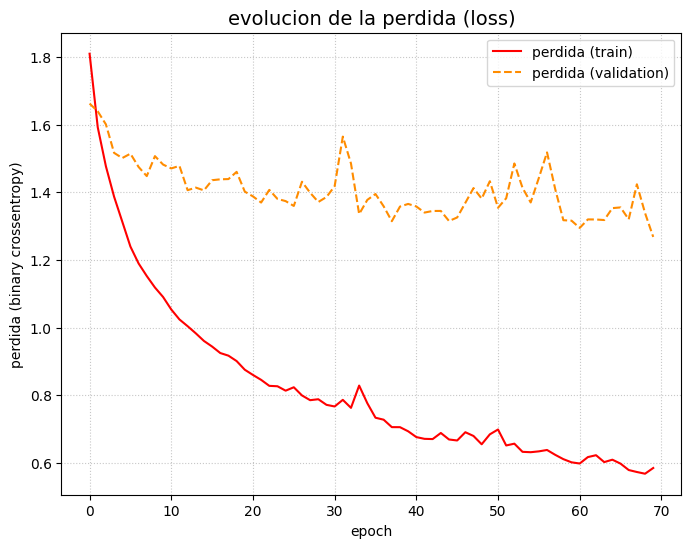

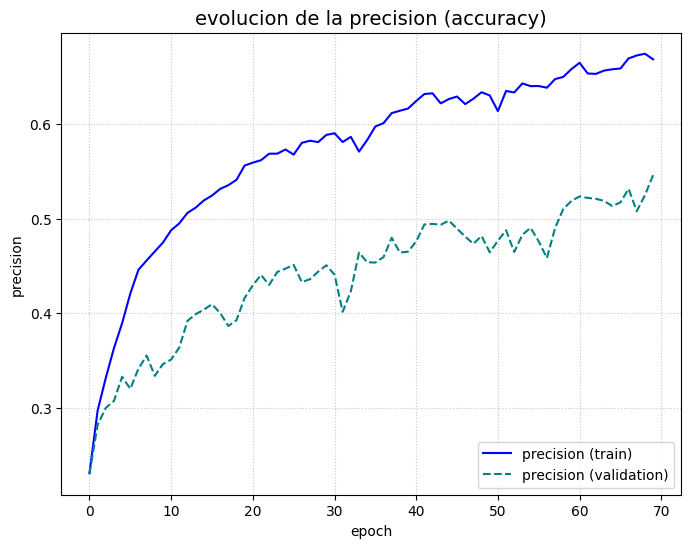

In [24]:
import matplotlib.pyplot as plt

# grafico 1: perdida (loss)
plt.figure(figsize=(8, 6))

# graficar la perdida de entrenamiento y validacion
plt.plot(history_mlp.history['loss'], label='perdida (train)', color='red')
plt.plot(history_mlp.history['val_loss'], label='perdida (validation)', color='darkorange', linestyle='--')

plt.title('evolucion de la perdida (loss)', fontsize=14)
plt.ylabel('perdida (binary crossentropy)')
plt.xlabel('epoch')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# grafico 2: precision (accuracy)
plt.figure(figsize=(8, 6))

# graficar la precision de entrenamiento y validacion
plt.plot(history_mlp.history['accuracy'], label='precision (train)', color='blue')
plt.plot(history_mlp.history['val_accuracy'], label='precision (validation)', color='teal', linestyle='--')

plt.title('evolucion de la precision (accuracy)', fontsize=14)
plt.ylabel('precision')
plt.xlabel('epoch')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

Predicciones del MLP sobre cinco imágenes de validación, con la probabilidad asignada a cada clase:

1/1 [==============================] - 0s 17ms/step
Nombres de las clases (índice 0 a 6): ['Big Truck', 'City Car', 'Multi Purpose Vehicle', 'Sedan', 'Sport Utility Vehicle', 'Truck', 'Van']

--------------------------------------------------
                 IMAGEN 1
--------------------------------------------------


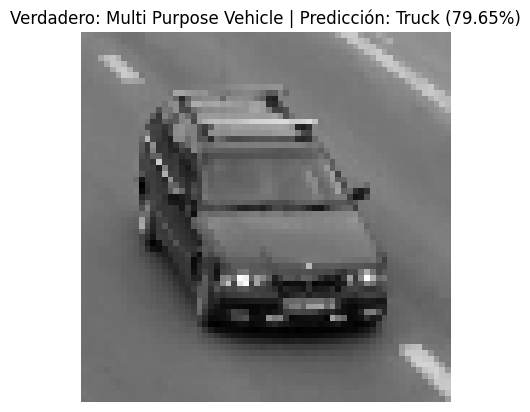


Probabilidades para todas las clases:
  -> Big Truck: 0.00% 
  -> City Car: 5.07% 
  -> Multi Purpose Vehicle: 4.55% 
  -> Sedan: 0.69% 
  -> Sport Utility Vehicle: 2.29% 
  -> Truck: 79.65% <- (Pred)
  -> Van: 7.74% 



--------------------------------------------------
                 IMAGEN 2
--------------------------------------------------


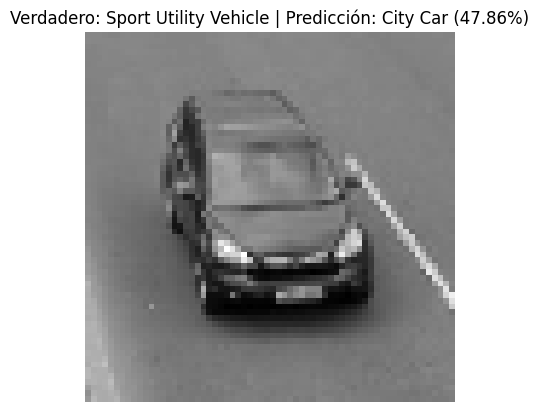


Probabilidades para todas las clases:
  -> Big Truck: 0.00% 
  -> City Car: 47.86% <- (Pred)
  -> Multi Purpose Vehicle: 8.26% 
  -> Sedan: 33.83% 
  -> Sport Utility Vehicle: 7.81% 
  -> Truck: 0.09% 
  -> Van: 2.15% 



--------------------------------------------------
                 IMAGEN 3
--------------------------------------------------


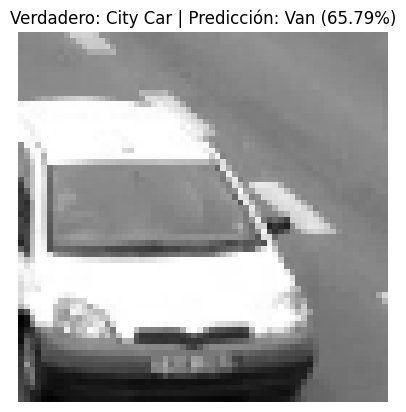


Probabilidades para todas las clases:
  -> Big Truck: 0.13% 
  -> City Car: 4.19% 
  -> Multi Purpose Vehicle: 4.45% 
  -> Sedan: 8.68% 
  -> Sport Utility Vehicle: 2.38% 
  -> Truck: 14.38% 
  -> Van: 65.79% <- (Pred)



--------------------------------------------------
                 IMAGEN 4
--------------------------------------------------


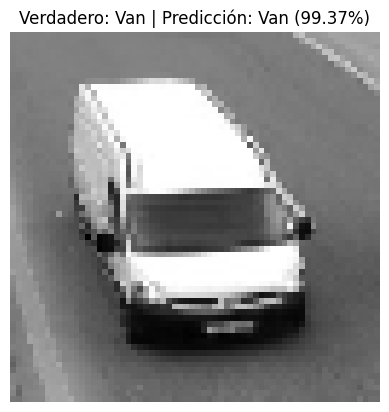


Probabilidades para todas las clases:
  -> Big Truck: 0.00% 
  -> City Car: 0.01% 
  -> Multi Purpose Vehicle: 0.03% 
  -> Sedan: 0.00% 
  -> Sport Utility Vehicle: 0.00% 
  -> Truck: 0.59% 
  -> Van: 99.37% <- (Pred)



--------------------------------------------------
                 IMAGEN 5
--------------------------------------------------


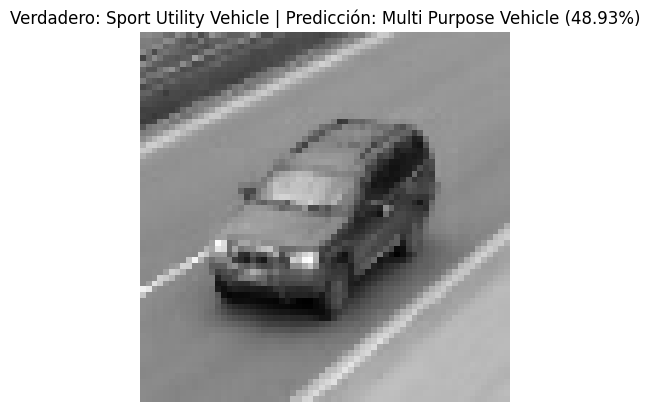


Probabilidades para todas las clases:
  -> Big Truck: 0.00% 
  -> City Car: 22.46% 
  -> Multi Purpose Vehicle: 48.93% <- (Pred)
  -> Sedan: 1.09% 
  -> Sport Utility Vehicle: 11.62% 
  -> Truck: 3.01% 
  -> Van: 12.89% 





In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Obtener un lote de datos del dataset de validación
sample_batch = next(iter(validation_dataset_mlp))
sample_images = sample_batch[0]  
sample_labels = sample_batch[1]  

# 2. Seleccionar 5 del lote
images_to_predict = sample_images[:5]
true_labels = sample_labels[:5]


predictions = model_mlp.predict(images_to_predict)


class_names = class_names
print(f"Nombres de las clases (índice 0 a 6): {class_names}\n")

# iterar y mostrar los resultados de cada imagen
for i in range(5):
    print("--------------------------------------------------")
    print(f"                 IMAGEN {i+1}")
    print("--------------------------------------------------")

    # obtener la etiqueta verdadera
    true_index = true_labels[i].numpy()
    true_name = class_names[true_index]

    # obtener la predicción del modelo
    predicted_index = np.argmax(predictions[i])
    predicted_name = class_names[predicted_index]
    confidence = 100 * np.max(predictions[i])

    # Mostrar la imagen
    # .squeeze() elimina la dimension del canal (64, 64, 1) -> (64, 64)
    plt.imshow(images_to_predict[i].numpy().squeeze(), cmap='gray')
    plt.title(f"Verdadero: {true_name} | Predicción: {predicted_name} ({confidence:.2f}%)")
    plt.axis('off')
    plt.show()

    # Mostrar el desglose de probabilidades
    print("\nProbabilidades para todas las clases:")
    for j in range(len(class_names)):
        prob = predictions[i][j] * 100
        # Añadir un indicador "<-" a la clase predicha para verla facil
        indicator = "<- (Pred)" if j == predicted_index else ""
        print(f"  -> {class_names[j]}: {prob:.2f}% {indicator}")

    print("\n\n")

**Valoración del MLP.** Un clasificador aleatorio acertaría el 14,3 % de las veces (1/7), y uno que siempre predijera la clase mayoritaria (*City Car*), el 29,8 % (4.657 / 15.645). El MLP llega a un 54 % aproximadamente: aprende algo, pero está lejos de ser útil. Además, la pérdida de validación apenas mejora a partir de la época 20 mientras la de entrenamiento sigue cayendo, y la diferencia entre ambas exactitudes crece hasta el final (67 % frente a 54 %): el modelo sobreajusta y mejora muy poco en validación. Al aplanar la imagen pierde toda la estructura espacial, que es precisamente lo que aprovecha una red convolucional.

## 3. CNN propia

Las convoluciones comparten pesos entre posiciones de la imagen, así que el número de parámetros no crece con la resolución como en el MLP. Eso permite usar imágenes RGB de 128×128.

In [10]:
IMAGE_SIZE = (128, 128)

train_dataset_cnn = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',
    label_mode='int',
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    interpolation='bilinear',
    color_mode='rgb',
    shuffle=True,
    validation_split=VALIDATION_AMOUNT,
    subset='training',
    seed=42 
)

validation_dataset_cnn = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    labels='inferred',
    label_mode='int',
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    interpolation='bilinear',
    color_mode='rgb',
    shuffle=True, 
    validation_split=VALIDATION_AMOUNT, 
    subset='validation',               
    seed=42                            
)


class_names = train_dataset_cnn.class_names

# Para el entrenamiento
train_dataset_cnn = train_dataset_cnn.prefetch(buffer_size=tf.data.AUTOTUNE)

# Para la validación
validation_dataset_cnn = validation_dataset_cnn.prefetch(buffer_size=tf.data.AUTOTUNE)

Found 15645 files belonging to 7 classes.
Using 12516 files for training.
Found 15645 files belonging to 7 classes.
Using 3129 files for validation.


**Arquitectura.** Cuatro bloques Conv 3×3 + BatchNorm + MaxPool (de 32 a 256 filtros), que aprenden características cada vez más abstractas: bordes, formas, partes del vehículo y objetos completos. Les siguen un global average pooling, que reduce mucho los parámetros frente a un aplanado, y un clasificador denso con dropout. Adam con learning rate de 1e-4, reducción del learning rate al estancarse la validación y early stopping. Esta primera versión no usa augmentation ni pesos de clase.

*El registro de esta ejecución no se conservó: la salida de la celda se perdió al volver a ejecutarla. Sus curvas, guardadas en la celda siguiente, muestran una exactitud en validación de aproximadamente el 86 %.*

In [6]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

model_cnn = tf.keras.Sequential([
        # Normalización de [0, 255] a [0, 1]
        tf.keras.layers.Rescaling(1./255, input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)),
        # Bloque 1: bordes y colores
        tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(), # Estabiliza el aprendizaje
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Bloque 2: formas
        tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Bloque 3: partes como ruedas o ventanas
        tf.keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Bloque 4: objetos
        tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Clasificador
        tf.keras.layers.GlobalAveragePooling2D(), # Mejor que Flatten para evitar overfitting
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.2), # Evita que el modelo memorice
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(num_classes, activation='softmax')
])

mi_optimizador = tf.keras.optimizers.Adam(learning_rate=0.0001)

model_cnn.compile(
    optimizer=mi_optimizador,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn.summary()

print("\n--- Iniciando Entrenamiento del cnn ---")

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

history_cnn = model_cnn.fit(
    train_dataset_cnn, #se pasa generador de train
    validation_data=validation_dataset_cnn, #se pasa generador de test
    epochs=100,
    verbose=1,
    #class_weight=class_weight_dict,
    callbacks=[reduce_lr, early_stop]
)

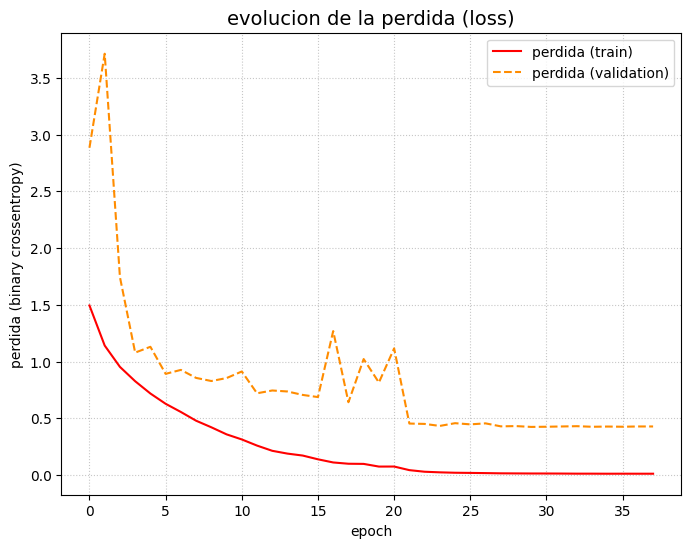

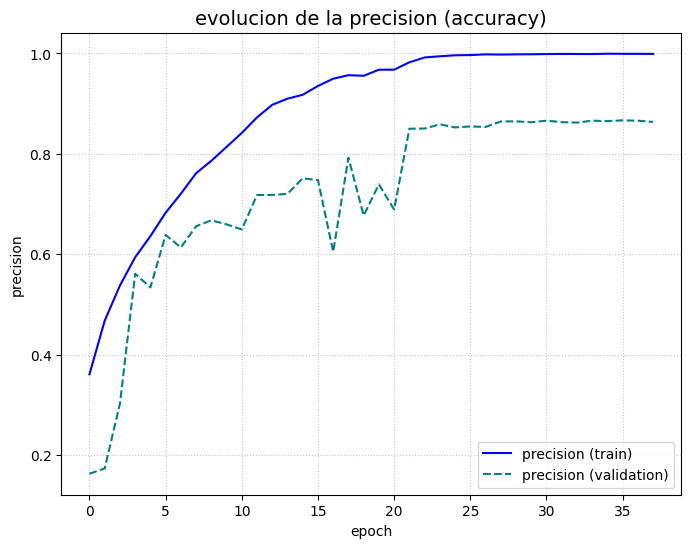

In [10]:
# grafico 1: perdida (loss)
plt.figure(figsize=(8, 6))

# graficar la perdida de entrenamiento y validacion
plt.plot(history_cnn.history['loss'], label='perdida (train)', color='red')
plt.plot(history_cnn.history['val_loss'], label='perdida (validation)', color='darkorange', linestyle='--')

plt.title('evolucion de la perdida (loss)', fontsize=14)
plt.ylabel('perdida (binary crossentropy)')
plt.xlabel('epoch')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# grafico 2: precision (accuracy)
plt.figure(figsize=(8, 6))

# graficar la precision de entrenamiento y validacion
plt.plot(history_cnn.history['accuracy'], label='precision (train)', color='blue')
plt.plot(history_cnn.history['val_accuracy'], label='precision (validation)', color='teal', linestyle='--')

plt.title('evolucion de la precision (accuracy)', fontsize=14)
plt.ylabel('precision')
plt.xlabel('epoch')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

**Diagnóstico:** sobreajuste claro. La exactitud de entrenamiento llega al 100 % mientras la de validación se queda en torno al 86 %. El modelo memoriza las imágenes de entrenamiento.

### CNN propia con data augmentation y pesos de clase

Para reducir el sobreajuste se añade data augmentation dentro del modelo, de modo que solo actúa durante el entrenamiento:

- **Volteo horizontal:** un vehículo puede aparecer orientado hacia la izquierda o hacia la derecha.
- **Rotaciones pequeñas (±11°), traslaciones (±10 %) y zoom (±10 %):** variaciones realistas de encuadre.

También se añaden los pesos de clase, se sube el dropout a 0,3 y el learning rate a 2e-4, y se da más paciencia a los callbacks, porque con augmentation el aprendizaje es más lento.

In [ ]:
model_cnn = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)),
    
    # Normalización de [0, 255] a [0, 1]
        tf.keras.layers.Rescaling(1./255),
    # Data augmentation (solo activa durante el entrenamiento)
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.03),
        tf.keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
        tf.keras.layers.RandomZoom(0.1),

        
        # Bloque 1: bordes y colores
        tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(), # Estabiliza el aprendizaje
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Bloque 2: formas
        tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Bloque 3: partes como ruedas o ventanas
        tf.keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Bloque 4: objetos
        tf.keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.MaxPooling2D((2, 2)),
        # Clasificador
        tf.keras.layers.GlobalAveragePooling2D(), # Mejor que Flatten para evitar overfitting
        tf.keras.layers.Dense(256, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3), # Evita que el modelo memorice
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dense(num_classes, activation='softmax')
])

mi_optimizador = tf.keras.optimizers.Adam(learning_rate=0.0002)

model_cnn.compile(
    optimizer=mi_optimizador,
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn.summary()

print("\n--- Iniciando Entrenamiento del cnn ---")

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=7, min_lr=1e-7, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_cnn = model_cnn.fit(
    train_dataset_cnn, #se pasa generador de train
    validation_data=validation_dataset_cnn, #se pasa generador de test
    epochs=100,
    verbose=1,
    workers=5,
    class_weight=class_weight_dict,
    callbacks=[reduce_lr, early_stop]
)

Model: "sequential_21"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling_15 (Rescaling)    (None, 128, 128, 3)       0         
                                                                 
 random_flip_13 (RandomFlip  (None, 128, 128, 3)       0         
 )                                                               
                                                                 
 random_rotation_13 (Random  (None, 128, 128, 3)       0         
 Rotation)                                                       
                                                                 
 random_translation_13 (Ran  (None, 128, 128, 3)       0         
 domTranslation)                                                 
                                                                 
 random_zoom_13 (RandomZoom  (None, 128, 128, 3)       0         
 )                                                   

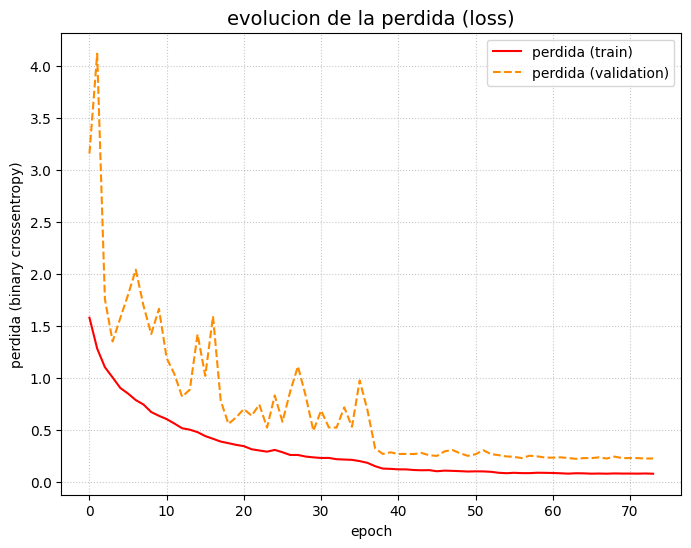

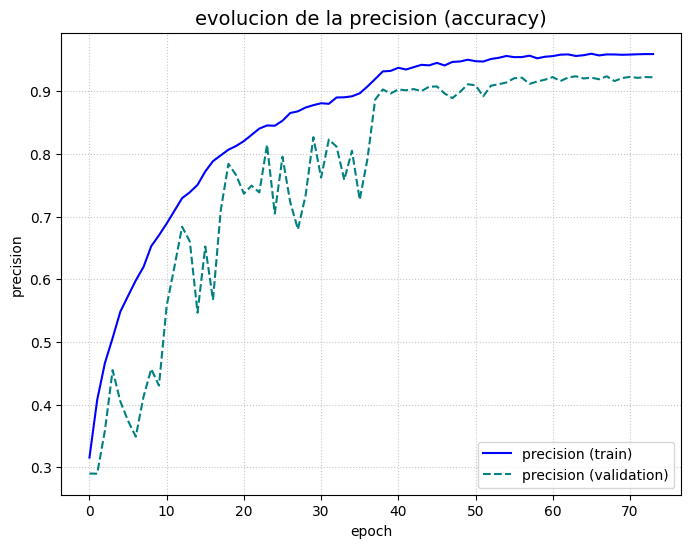

In [33]:
# grafico 1: perdida (loss)
plt.figure(figsize=(8, 6))

# graficar la perdida de entrenamiento y validacion
plt.plot(history_cnn.history['loss'], label='perdida (train)', color='red')
plt.plot(history_cnn.history['val_loss'], label='perdida (validation)', color='darkorange', linestyle='--')

plt.title('evolucion de la perdida (loss)', fontsize=14)
plt.ylabel('perdida (binary crossentropy)')
plt.xlabel('epoch')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

# grafico 2: precision (accuracy)
plt.figure(figsize=(8, 6))

# graficar la precision de entrenamiento y validacion
plt.plot(history_cnn.history['accuracy'], label='precision (train)', color='blue')
plt.plot(history_cnn.history['val_accuracy'], label='precision (validation)', color='teal', linestyle='--')

plt.title('evolucion de la precision (accuracy)', fontsize=14)
plt.ylabel('precision')
plt.xlabel('epoch')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

**Resultado:** la exactitud en validación sube al **92,4 %** (época 64) y la diferencia con entrenamiento se reduce a unos 3 puntos (95,6 % frente a 92,4 %). La augmentation reduce el sobreajuste y mejora el resultado en unos 6 puntos.

**Comprobación de los pesos de clase.** Los pesos de la sección 2 se estimaron a partir del conteo total de cada clase. Calculándolos con las etiquetas reales del conjunto de entrenamiento, los valores difieren menos de un 2 %:

In [10]:
import numpy as np
from sklearn.utils import class_weight
import tensorflow as tf

# 1. Extraemos todas las etiquetas (y) de tu dataset de entrenamiento
train_labels = []
print("Extrayendo etiquetas del dataset para calcular pesos...")

# Iteramos sobre el dataset (que viene por lotes) solo para sacar las 'labels'
for images, labels in train_dataset_cnn:
    train_labels.extend(labels.numpy())

# Convertimos a array de numpy
train_labels = np.array(train_labels)

# 2. Calculamos los pesos usando sklearn
weights_array = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

# 3. Convertimos a diccionario (formato que pide Keras)
class_weights_dict = dict(enumerate(weights_array))

print("Etiquetas encontradas:", len(train_labels))
print("Pesos calculados:", class_weights_dict)

Extrayendo etiquetas del dataset para calcular pesos...
Etiquetas encontradas: 12516
Pesos calculados: {0: np.float64(3.878524945770065), 1: np.float64(0.48220064724919093), 2: np.float64(0.8402255639097744), 3: np.float64(0.8596153846153847), 4: np.float64(1.2204778156996587), 5: np.float64(1.9184549356223175), 6: np.float64(1.026406429391504)}


## 4. Transfer learning con MobileNetV2

MobileNetV2 es una red ligera preentrenada en ImageNet. Se usa a su resolución nativa (224×224) con su propio preprocesado, y se entrena en dos fases:

1. **Base congelada:** solo se entrena la nueva cabeza clasificadora (global average pooling, una capa densa de 256 neuronas con dropout de 0,4 y la capa de salida).
2. **Fine-tuning:** se descongelan las capas superiores de la base (de la 100 en adelante) y se entrenan con un learning rate muy bajo, para ajustar las características de ImageNet a los vehículos sin destruirlas.

*Nota: esta partición usa la semilla 123, distinta de la de los modelos anteriores (42), así que el conjunto de validación no es exactamente el mismo.*

In [17]:
IMG_SIZE_TL = (224, 224) 
BATCH_SIZE = 32 # bajar porque sube la resolucion

train_ds_tl = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE_TL,
    batch_size=BATCH_SIZE,
    label_mode='int',
    color_mode='rgb'
)

val_ds_tl = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE_TL,
    batch_size=BATCH_SIZE,
    label_mode='int',
    color_mode='rgb'
)

# Preprocesamiento de MobileNetV2
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

# Aplicar preprocesamiento al dataset
train_ds_tl = train_ds_tl.map(lambda x, y: (preprocess_input(x), y))
val_ds_tl = val_ds_tl.map(lambda x, y: (preprocess_input(x), y))

Found 15645 files belonging to 7 classes.
Using 12516 files for training.
Found 15645 files belonging to 7 classes.
Using 3129 files for validation.


**Construcción del modelo:**

In [ ]:
from tensorflow.keras import layers, models
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False, 
    weights='imagenet'
)

# congelar el modelo base (para no destruir lo que ya "sabe")
base_model.trainable = False

# Crear tu modelo final
inputs = tf.keras.Input(shape=(224, 224, 3))

# Aumento de datos para evitar overfitting
x = layers.RandomFlip('horizontal')(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)


x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x) 
x = layers.Dropout(0.4)(x) # Dropout para evitar overfitting

# Capa de salida (7 clases)
outputs = layers.Dense(7, activation='softmax')(x)

model_tl = tf.keras.Model(inputs, outputs)

model_tl.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model_tl.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_8 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 random_flip_2 (RandomFlip)  (None, 224, 224, 3)       0         
                                                                 
 random_rotation_2 (RandomR  (None, 224, 224, 3)       0         
 otation)                                                        
                                                                 
 random_zoom_1 (RandomZoom)  (None, 224, 224, 3)       0         
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d_2  (None, 1280)              0   

**Fase 1 (12 épocas con la base congelada) y primera ronda de fine-tuning (4 épocas).** Con la base congelada, la exactitud en validación se queda en el 67 %. Al empezar el fine-tuning sube rápidamente, hasta el 75,5 %.

In [ ]:
# FASE 1: Entrenar solo la cabeza clasificadora
print("--- FASE 1: Entrenando solo la nueva capa ---")
history_tl = model_tl.fit(
    train_ds_tl,
    epochs=12, 
    validation_data=val_ds_tl,
    class_weight=class_weight_dict 
)

print("--- FASE 2: Descongelando capas superiores ---")
base_model.trainable = True

# Congelamos las primeras capas primeras 100
fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# recompilar con un learning rate MUY bajo para que no cambie mucho la parte convolucional
model_tl.compile(optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.00001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history_fine = model_tl.fit(

    
    train_ds_tl,
    epochs=15, 
    initial_epoch=history_tl.epoch[-1],
    validation_data=val_ds_tl,
    class_weight=class_weight_dict
)

--- FASE 1: Entrenando solo la nueva capa ---
Epoch 1/12
392/392 [==============================] - 199s 496ms/step - loss: 1.1459 - accuracy: 0.4604 - val_loss: 1.1021 - val_accuracy: 0.5184
Epoch 2/12
392/392 [==============================] - 222s 565ms/step - loss: 0.9223 - accuracy: 0.5329 - val_loss: 0.9814 - val_accuracy: 0.5909
Epoch 3/12
392/392 [==============================] - 221s 563ms/step - loss: 0.8417 - accuracy: 0.5617 - val_loss: 0.9988 - val_accuracy: 0.5737
Epoch 4/12
392/392 [==============================] - 220s 562ms/step - loss: 0.8145 - accuracy: 0.5805 - val_loss: 0.9257 - val_accuracy: 0.6114
Epoch 5/12
392/392 [==============================] - 220s 563ms/step - loss: 0.7602 - accuracy: 0.6043 - val_loss: 0.8410 - val_accuracy: 0.6488
Epoch 6/12
392/392 [==============================] - 191s 487ms/step - loss: 0.7568 - accuracy: 0.6087 - val_loss: 0.9061 - val_accuracy: 0.6213
Epoch 7/12
392/392 [==============================] - 68s 173ms/step - loss: 0

**Segunda ronda de fine-tuning.** Se continúa entrenando el mismo modelo con más épocas, Adam con learning rate de 1e-5, early stopping (paciencia 8), guardado del mejor modelo y reducción del learning rate al estancarse la validación. El early stopping se detuvo en la época 43 y restauró los pesos de la época 35 (menor pérdida de validación): **89,6 %** de exactitud en validación.

In [20]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
print("--- FASE 2: Descongelando capas superiores ---")

base_model.trainable = True

fine_tune_at = 100
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model_tl.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), 
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# --- CALLBACKS ---
callbacks_list = [
    EarlyStopping(monitor='val_loss', patience=8, verbose=1, restore_best_weights=True),
    ModelCheckpoint('mejor_modelo_mobilenet.keras', monitor='val_loss', save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)
]

# Entrenamos hasta la epoch 50
total_epochs = 50 

history_fine = model_tl.fit(
    train_ds_tl,
    epochs=total_epochs,
    initial_epoch=history_tl.epoch[-1], # Continua donde lo dejo la Fase 1
    validation_data=val_ds_tl,
    callbacks=callbacks_list #callbacks
)

--- FASE 2: Descongelando capas superiores ---
Epoch 12/50
392/392 [==============================] - ETA: 0s - loss: 0.6036 - accuracy: 0.7544
Epoch 12: val_loss improved from inf to 0.51049, saving model to mejor_modelo_mobilenet.keras
392/392 [==============================] - 327s 807ms/step - loss: 0.6036 - accuracy: 0.7544 - val_loss: 0.5105 - val_accuracy: 0.8003 - lr: 1.0000e-05
Epoch 13/50
392/392 [==============================] - ETA: 0s - loss: 0.5582 - accuracy: 0.7729
Epoch 13: val_loss did not improve from 0.51049
392/392 [==============================] - 280s 714ms/step - loss: 0.5582 - accuracy: 0.7729 - val_loss: 0.5134 - val_accuracy: 0.7942 - lr: 1.0000e-05
Epoch 14/50
392/392 [==============================] - ETA: 0s - loss: 0.5222 - accuracy: 0.7878
Epoch 14: val_loss improved from 0.51049 to 0.44591, saving model to mejor_modelo_mobilenet.keras
392/392 [==============================] - 299s 762ms/step - loss: 0.5222 - accuracy: 0.7878 - val_loss: 0.4459 - val_

## 5. Resultados y conclusiones

| Modelo | Exactitud en validación | Exactitud en entrenamiento | Parámetros entrenables |
| :--- | :---: | :---: | :---: |
| MLP (64×64, grises) | ≈ 54 % | ≈ 67 % | 533.127 |
| CNN propia, sin augmentation | ≈ 86 % | 100 % | — |
| **CNN propia + augmentation + pesos de clase** | **92,4 %** | 96 % | 489.479 |
| MobileNetV2 (fine-tuning) | 89,6 % | 89 % | — |

Las exactitudes de las CNN y de MobileNetV2 corresponden a la época con menor pérdida de validación; las del MLP y la CNN sin augmentation se leen de sus curvas.

**Conclusiones**

- **Las convoluciones son la clave.** Pasar del MLP a una CNN, con menos parámetros, sube la exactitud de un 54 % a un 86 % aproximadamente, porque la CNN aprovecha la estructura espacial de la imagen.
- **La data augmentation es la mejora más rentable.** Reduce el sobreajuste (la diferencia entre entrenamiento y validación pasa de unos 14 a unos 3 puntos) y añade unos 6 puntos de exactitud.
- **Un modelo pequeño entrenado desde cero supera al transfer learning.** La CNN propia (unos 490.000 parámetros) supera a MobileNetV2 (92,4 % frente a 89,6 %). Una posible explicación es que el dataset es lo bastante grande y homogéneo para entrenar desde cero. En cualquier caso, MobileNetV2 se evaluó sobre otra partición de validación, así que una diferencia de 3 puntos no es concluyente.

**Limitaciones de la evaluación**

- **No hay conjunto de test independiente.** La validación se usa también para el early stopping y la reducción del learning rate, así que las cifras son algo optimistas.
- **Solo se mide la exactitud.** Con clases desbalanceadas faltan la matriz de confusión y el macro-F1 para ver el rendimiento en las clases minoritarias, como *Big Truck*.
- **MobileNetV2 usa otra partición** (semilla 123), así que su comparación con las CNN es aproximada.

**Siguientes pasos:** partición fija train/val/test común a todos los modelos, matriz de confusión y macro-F1 por modelo, y un fine-tuning más largo de MobileNetV2 (o de otro modelo preentrenado, como EfficientNet) en igualdad de condiciones.